# Chapitre 4 — Not every country starts with the same cards
### *The World That Never Happened* · COVID-19, attentes économiques et inégalité face à la reprise

**Question du chapitre :** pourquoi certaines économies étaient-elles plus vulnérables que d'autres ?

Les chapitres 1 à 3 ont montré *combien* chaque pays s'est écarté de la trajectoire prévue par le FMI en octobre 2019, et comment la crise sanitaire et les politiques publiques ont coïncidé avec ces écarts. Ici, on remonte **avant** la pandémie : avec quelles « cartes » structurelles chaque économie est-elle entrée dans le choc ?

**Variables de vulnérabilité (Banque mondiale, 2019)**

| Variable | Ce qu'elle mesure | Canal attendu |
|---|---|---|
| `tourism_receipts_pct_exports` | Recettes touristiques internationales, % des exportations | Fermeture des frontières, effondrement des voyages |
| `trade_pct_gdp` | Commerce (exports + imports), % du PIB | Rupture des chaînes de valeur, chute de la demande mondiale |
| `services_value_added_pct_gdp` | Part des services dans la valeur ajoutée | Secteurs « de contact » (restauration, loisirs…) |
| `oil_rents_pct_gdp` | Rentes pétrolières, % du PIB | Effondrement du prix du pétrole en 2020, puis boom en 2022 |
| groupe de revenu | Classification Banque mondiale | Capacité budgétaire et sanitaire à amortir le choc |

**Variable à expliquer :** le *forecast shortfall* (croissance réelle − prévision FMI oct. 2019), annuel et cumulé en niveau sur 2020–2022.

> ⚠️ **Rappel méthodologique.** La prévision d'octobre 2019 est un *benchmark*, pas le PIB d'un monde sans COVID. Un écart peut aussi refléter d'autres chocs (prix du pétrole, guerre en Ukraine en 2022, ralentissement déjà en cours…). Avec **11 pays**, les corrélations sont **descriptives** : elles décrivent ce panel, elles ne prouvent aucun lien causal.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})

DATA_DIR = "."   # dossier contenant les CSV

## 1. Chargement des données

In [2]:
vul    = pd.read_csv(f"{DATA_DIR}/world_bank_vulnerability_2019.csv")
gdp    = pd.read_csv(f"{DATA_DIR}/world_bank_gdp_growth.csv")
imf    = pd.read_csv(f"{DATA_DIR}/imf_gdp_growth_oct2019_long.csv")
policy = pd.read_csv(f"{DATA_DIR}/oxcgrt_policy_2020_2022.csv", parse_dates=["Date"])
health = pd.read_csv(f"{DATA_DIR}/owid_covid_health_2020_2022.csv", parse_dates=["date"])

# Noms courts harmonisés (le FMI dit "Korea", la Banque mondiale "Korea, Rep.")
NAMES = {"USA": "United States", "DEU": "Germany", "ESP": "Spain", "SWE": "Sweden",
         "CHN": "China", "IND": "India", "BRA": "Brazil", "ZAF": "South Africa",
         "THA": "Thailand", "KOR": "South Korea", "SAU": "Saudi Arabia"}

# Classification de revenu de la Banque mondiale (exercice 2020, basée sur le RNB/hab. 2018).
# Elle n'est pas dans les fichiers fournis : ajoutée manuellement.
INCOME = {"USA": "High income", "DEU": "High income", "ESP": "High income", "SWE": "High income",
          "KOR": "High income", "SAU": "High income",
          "CHN": "Upper-middle income", "BRA": "Upper-middle income",
          "ZAF": "Upper-middle income", "THA": "Upper-middle income",
          "IND": "Lower-middle income"}

# Couleurs fixes par pays : les mêmes pays restent reconnaissables d'un chapitre à l'autre
COUNTRY_COLORS = dict(zip(NAMES, sns.color_palette("tab20", 11).as_hex()))
INCOME_COLORS = {"High income": "#2b6cb0", "Upper-middle income": "#dd8452", "Lower-middle income": "#c44e52"}

print({k: len(v) for k, v in dict(vul=vul, gdp=gdp, imf=imf, policy=policy, health=health).items()})
vul

{'vul': 11, 'gdp': 143, 'imf': 66, 'policy': 12056, 'health': 12056}


,ISO3,country,oil_rents_pct_gdp,services_value_added_pct_gdp,tourism_receipts_pct_exports,trade_pct_gdp
0,USA,United States,0.37,76.61,9.38,26.26
1,DEU,Germany,0.01,63.01,3.47,79.07
2,ESP,Spain,0.00,68.27,NaN,66.37
3,SWE,Sweden,0.03,65.04,NaN,92.75
4,CHN,China,0.30,55.23,NaN,35.45
5,IND,India,0.31,50.08,5.80,39.91
6,BRA,Brazil,1.68,63.07,2.37,28.89
7,ZAF,South Africa,0.37,64.35,8.56,53.90
8,THA,Thailand,0.46,58.28,19.88,109.69
9,KOR,"Korea, Rep.",0.02,56.94,3.85,71.45


### Contrôle qualité : données manquantes

Point crucial pour ce chapitre : **les recettes touristiques sont absentes pour l'Espagne, la Suède et la Chine**. Or l'Espagne est précisément l'économie la plus touristique du panel — c'est elle qui a subi le plus gros choc en 2020 (-12,8 points sous la prévision). L'analyse « tourisme » porte donc sur **8 pays seulement**, et le pays qui illustrerait le mieux l'hypothèse en est exclu. Il faut le dire explicitement dans le dashboard.

In [3]:
missing = vul.set_index("ISO3").drop(columns="country").isna()
print("Valeurs manquantes par variable :\n", missing.sum(), "\n")
print("Pays sans donnée tourisme :", [NAMES[c] for c in missing.index[missing["tourism_receipts_pct_exports"]]])

# OPTIONNEL : si votre groupe récupère la valeur manquante sur une autre année
# (indicateur Banque mondiale ST.INT.RCPT.XP.ZS, ex. 2018), renseignez-la ici et
# documentez la source. Laissé vide par défaut : aucune valeur inventée.
TOURISM_FILL = {}   # ex. {"ESP": valeur_2018}
for iso, val in TOURISM_FILL.items():
    vul.loc[vul.ISO3 == iso, "tourism_receipts_pct_exports"] = val

Valeurs manquantes par variable :
 oil_rents_pct_gdp               0
services_value_added_pct_gdp    0
tourism_receipts_pct_exports    3
trade_pct_gdp                   0
dtype: int64 

Pays sans donnée tourisme : ['Spain', 'Sweden', 'China']


## 2. La variable à expliquer : l'écart à la prévision

On calcule deux mesures :

1. **L'écart annuel** = croissance réelle − prévision FMI (en points de %). Négatif = pire que prévu.
2. **L'écart cumulé en niveau fin 2022** : on compare le niveau de PIB effectivement atteint en 2022 au niveau qu'impliquaient les prévisions pour 2020-2021-2022 (base 2019 = 100). C'est la mesure la plus parlante : *« fin 2022, le PIB du pays est X % en dessous de ce qu'on attendait »*. Elle capte à la fois le choc et la reprise.

In [4]:
m = gdp.merge(imf[["ISO3", "year", "imf_gdp_growth_pct"]], on=["ISO3", "year"])
m["shortfall"] = m["gdp_growth_pct"] - m["imf_gdp_growth_pct"]
short = m.pivot(index="ISO3", columns="year", values="shortfall").add_prefix("shortfall_")

def level_index(df, col):
    w = df[df.year.between(2020, 2022)].pivot(index="ISO3", columns="year", values=col)
    return 100 * (1 + w / 100).prod(axis=1)

actual_lvl   = level_index(gdp, "gdp_growth_pct")
forecast_lvl = level_index(imf, "imf_gdp_growth_pct")
gap_2022 = (actual_lvl / forecast_lvl - 1) * 100

outcome = short.assign(level_gap_2022=gap_2022,
                       actual_index_2022=actual_lvl, forecast_index_2022=forecast_lvl)
outcome.index = outcome.index.map(NAMES)
outcome.sort_values("level_gap_2022").round(2)

year,shortfall_2019,shortfall_2020,shortfall_2021,shortfall_2022,level_gap_2022,actual_index_2022,forecast_index_2022
ISO3,,,,,,,
Thailand,-0.76,-9.10,-1.93,-1.01,-11.41,97.89,110.49
India,-2.25,-12.81,2.25,0.17,-9.98,111.22,123.55
Spain,-0.21,-12.79,4.98,4.70,-4.03,101.06,105.31
South Africa,-0.40,-7.25,3.42,0.30,-3.76,100.42,104.34
China,-0.07,-3.48,2.67,-2.57,-3.26,114.59,118.45
Germany,0.43,-5.38,2.47,0.47,-2.55,101.42,104.08
Brazil,0.35,-5.32,2.39,0.66,-2.37,104.39,106.92
South Korea,0.36,-2.92,1.86,-0.17,-1.25,106.71,108.07
Sweden,1.67,-3.40,3.17,-0.72,-1.04,104.49,105.59


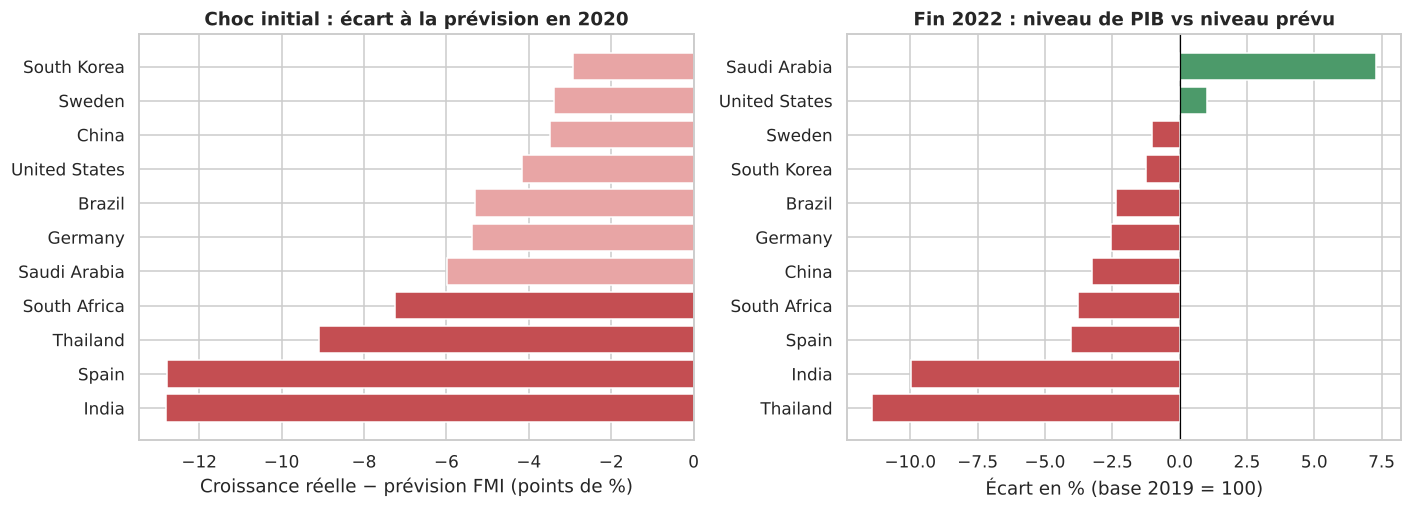

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=False)

o = outcome.sort_values("shortfall_2020")
axes[0].barh(o.index, o["shortfall_2020"], color=["#c44e52" if x < -7 else "#e8a5a5" for x in o["shortfall_2020"]])
axes[0].set_title("Choc initial : écart à la prévision en 2020")
axes[0].set_xlabel("Croissance réelle − prévision FMI (points de %)")

o = outcome.sort_values("level_gap_2022")
axes[1].barh(o.index, o["level_gap_2022"], color=["#c44e52" if x < 0 else "#4c9a6a" for x in o["level_gap_2022"]])
axes[1].axvline(0, color="black", lw=0.8)
axes[1].set_title("Fin 2022 : niveau de PIB vs niveau prévu")
axes[1].set_xlabel("Écart en % (base 2019 = 100)")
plt.tight_layout(); plt.show()

**Lecture.** Le choc de 2020 frappe tout le monde, mais pas avec la même intensité : l'Inde et l'Espagne perdent ~13 points par rapport à la prévision, la Corée et la Suède ~3. Fin 2022, la hiérarchie change : la **Thaïlande** (-11 %) et l'**Inde** (-10 %) restent loin de leur trajectoire, tandis que l'**Arabie saoudite** finit *au-dessus* (+7 %) — grâce au boom pétrolier de 2022, pas grâce à la pandémie. C'est cette dispersion que le chapitre cherche à relier aux vulnérabilités de départ.

## 3. Les cartes en main en 2019 : profils de vulnérabilité

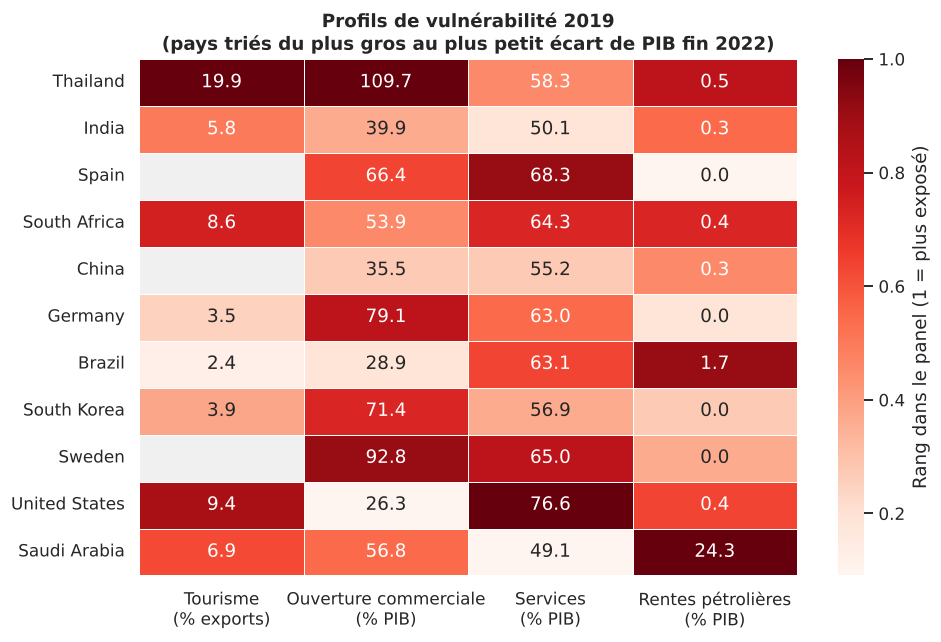

In [6]:
VARS = {"tourism_receipts_pct_exports": "Tourisme\n(% exports)",
        "trade_pct_gdp": "Ouverture commerciale\n(% PIB)",
        "services_value_added_pct_gdp": "Services\n(% PIB)",
        "oil_rents_pct_gdp": "Rentes pétrolières\n(% PIB)"}

prof = vul.set_index("ISO3")[list(VARS)].copy()
prof["income_group"] = pd.Series(INCOME)
prof.index = prof.index.map(NAMES)

# Rang centile dans le panel (0 = moins exposé, 1 = plus exposé) pour comparer des échelles différentes
heat = prof[list(VARS)].rank(pct=True)
heat = heat.loc[outcome["level_gap_2022"].sort_values().index]   # trié du pire au meilleur écart final

fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(heat.rename(columns=VARS), annot=prof.loc[heat.index, list(VARS)].round(1).values,
            fmt="", cmap="Reds", cbar_kws={"label": "Rang dans le panel (1 = plus exposé)"},
            linewidths=.5, linecolor="white", ax=ax, mask=heat.isna().values)
ax.grid(False); ax.set_facecolor("#f0f0f0")
ax.set_title("Profils de vulnérabilité 2019\n(pays triés du plus gros au plus petit écart de PIB fin 2022)")
ax.set_ylabel(""); ax.set_xlabel("")
plt.tight_layout(); plt.show()

**Lecture.** Les profils sont très différents :
- **Thaïlande** : exposition maximale sur deux canaux à la fois — 1ᵉʳ en tourisme (~20 % des exportations) et 1ᵉʳ en ouverture commerciale (~110 % du PIB). C'est aussi le pays le plus loin de sa trajectoire fin 2022.
- **Arabie saoudite** : vulnérabilité d'une autre nature, la dépendance au pétrole (24 % du PIB en rentes, quand tous les autres sont sous 2 %).
- **États-Unis** : économie la plus tertiarisée (77 %) mais très fermée (26 % du PIB en commerce).
- Les cases blanches rappellent le trou de données sur le tourisme (Espagne, Suède, Chine).

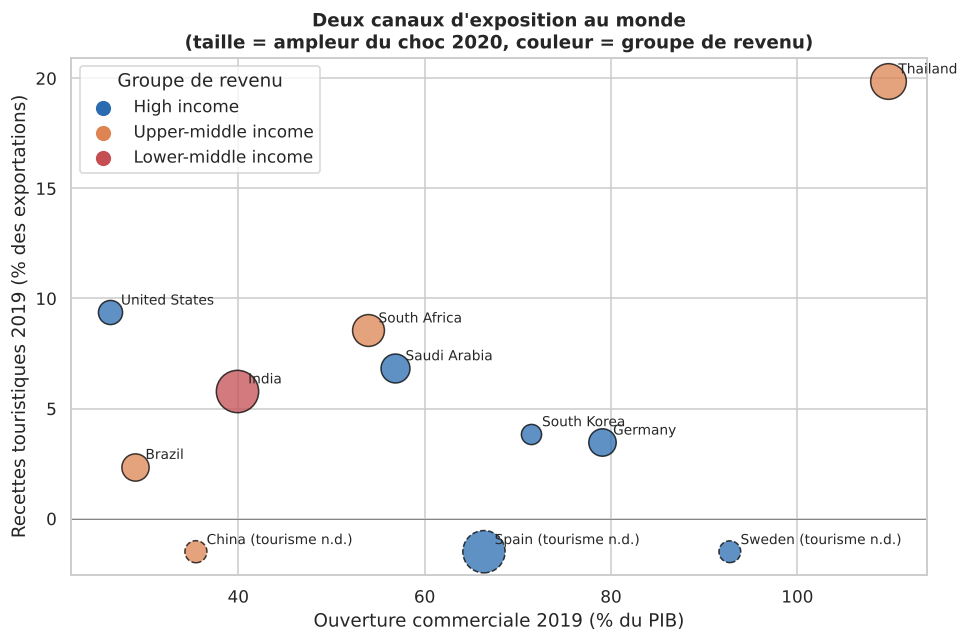

In [7]:
fig, ax = plt.subplots(figsize=(9, 6))
d = prof.join(outcome[["shortfall_2020", "level_gap_2022"]])
for name, r in d.iterrows():
    y = r["tourism_receipts_pct_exports"]
    missing_t = pd.isna(y)
    y = -1.5 if missing_t else y
    ax.scatter(r["trade_pct_gdp"], y, s=abs(r["shortfall_2020"]) * 60,
               color=INCOME_COLORS[r["income_group"]], alpha=.75,
               edgecolor="black", linestyle="--" if missing_t else "-", lw=1)
    ax.annotate(name + (" (tourisme n.d.)" if missing_t else ""), (r["trade_pct_gdp"], y),
                xytext=(7, 5), textcoords="offset points", fontsize=9)
ax.axhline(0, color="grey", lw=.6)
ax.set_xlabel("Ouverture commerciale 2019 (% du PIB)")
ax.set_ylabel("Recettes touristiques 2019 (% des exportations)")
ax.set_title("Deux canaux d'exposition au monde\n(taille = ampleur du choc 2020, couleur = groupe de revenu)")
for g, c in INCOME_COLORS.items():
    ax.scatter([], [], color=c, label=g, s=80)
ax.legend(title="Groupe de revenu", loc="upper left", frameon=True)
plt.tight_layout(); plt.show()

## 4. Les vulnérabilités expliquent-elles l'écart à la prévision ?

On croise chaque variable de vulnérabilité avec (a) le choc de 2020 et (b) l'écart cumulé fin 2022. On utilise la **corrélation de Spearman** (sur les rangs), plus robuste qu'une corrélation de Pearson quand on a 11 points et des valeurs extrêmes (Arabie saoudite pour le pétrole, Thaïlande pour le commerce).

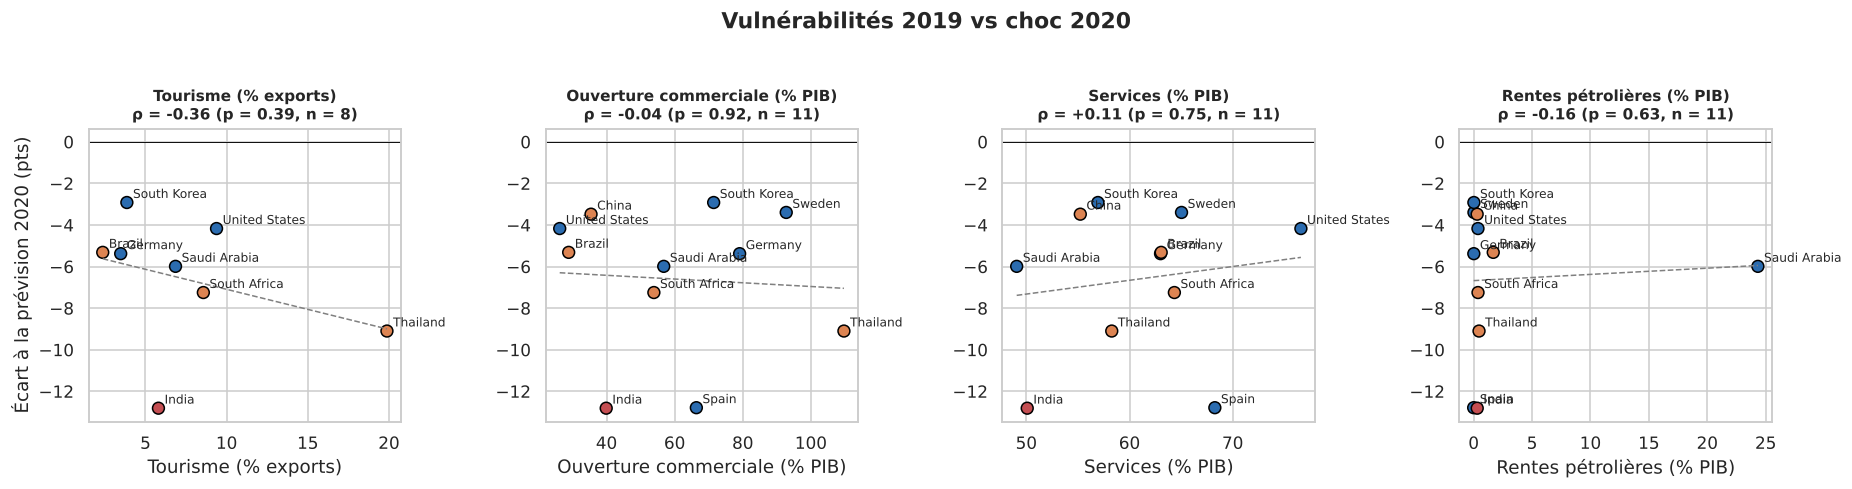

,n,spearman_rho,p_value,pearson_r
variable,,,,
Tourisme (% exports),8,-0.36,0.39,-0.34
Ouverture commerciale (% PIB),11,-0.04,0.92,-0.07
Services (% PIB),11,0.11,0.75,0.15
Rentes pétrolières (% PIB),11,-0.16,0.63,0.06


In [8]:
d = prof.join(outcome)

def scatter_grid(target, title, ylab):
    fig, axes = plt.subplots(1, 4, figsize=(17, 4.3))
    rows = []
    for ax, (var, lab) in zip(axes, VARS.items()):
        s = d[[var, target, "income_group"]].dropna()
        rho, p = stats.spearmanr(s[var], s[target])
        r_p, _ = stats.pearsonr(s[var], s[target])
        rows.append({"variable": lab.replace("\n", " "), "n": len(s), "spearman_rho": rho, "p_value": p, "pearson_r": r_p})
        ax.scatter(s[var], s[target], c=s["income_group"].map(INCOME_COLORS), s=60, edgecolor="black")
        for n, r in s.iterrows():
            ax.annotate(n, (r[var], r[target]), xytext=(4, 3), textcoords="offset points", fontsize=8)
        b = np.polyfit(s[var], s[target], 1)
        xx = np.linspace(s[var].min(), s[var].max(), 50)
        ax.plot(xx, np.polyval(b, xx), color="grey", ls="--", lw=1)
        ax.axhline(0, color="black", lw=.6)
        ax.set_title(f"{lab.replace(chr(10), ' ')}\nρ = {rho:+.2f} (p = {p:.2f}, n = {len(s)})", fontsize=10)
        ax.set_xlabel(lab.replace("\n", " "))
    axes[0].set_ylabel(ylab)
    fig.suptitle(title, fontweight="bold", y=1.03)
    plt.tight_layout(); plt.show()
    return pd.DataFrame(rows).set_index("variable")

corr_2020 = scatter_grid("shortfall_2020", "Vulnérabilités 2019 vs choc 2020", "Écart à la prévision 2020 (pts)")
corr_2020

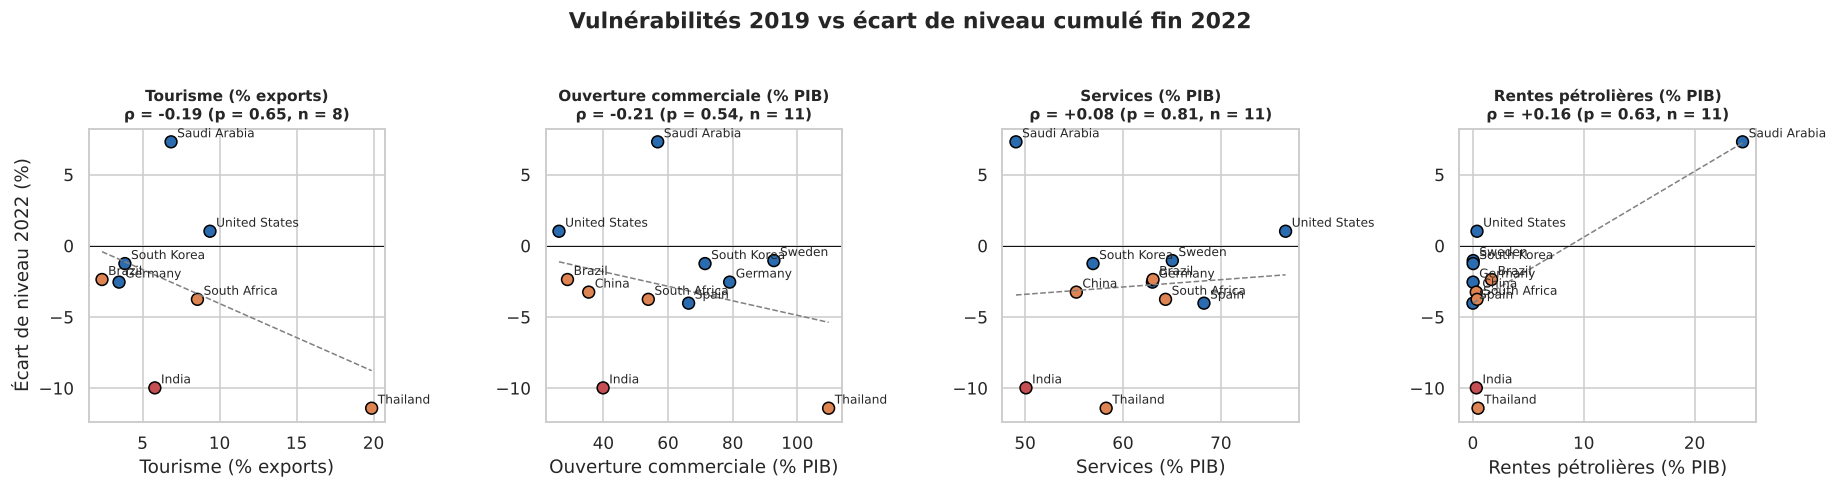

,n,spearman_rho,p_value,pearson_r
variable,,,,
Tourisme (% exports),8,-0.19,0.65,-0.45
Ouverture commerciale (% PIB),11,-0.21,0.54,-0.27
Services (% PIB),11,0.08,0.81,0.08
Rentes pétrolières (% PIB),11,0.16,0.63,0.67


In [9]:
corr_2022 = scatter_grid("level_gap_2022", "Vulnérabilités 2019 vs écart de niveau cumulé fin 2022", "Écart de niveau 2022 (%)")
corr_2022

**Lecture — c'est le résultat central du chapitre, et il est nuancé.**

- **Aucune variable seule n'explique bien le classement.** Toutes les corrélations sont faibles et aucune n'est statistiquement significative (p > 0,3). Avec 11 pays, c'est attendu, mais c'est aussi un message : *la structure économique ne détermine pas mécaniquement le destin d'un pays face au choc.*
- **Le tourisme va dans le sens attendu** (ρ ≈ -0,36 en 2020) : plus un pays dépend du tourisme, plus il est tombé sous sa prévision. Mais le test est affaibli par l'absence de l'Espagne — qui aurait très probablement renforcé la relation.
- **L'ouverture commerciale ne joue presque pas en 2020** (ρ ≈ 0). La Corée, l'Allemagne et la Suède, très ouvertes, ont subi des chocs modérés : le commerce de biens s'est vite redressé (forte demande de biens durables, électronique), contrairement aux services touristiques.
- **Le pétrole est un cas à part** : la corrélation de Pearson avec l'écart 2022 (≈ +0,67) est entièrement portée par un seul point, l'Arabie saoudite, dont la reprise vient de la flambée des prix de 2022. C'est un exemple de *forecast error* qui n'a rien à voir avec le COVID.

### Robustesse : que se passe-t-il si on retire un pays ?

Avec 11 points, un seul pays peut fabriquer ou détruire une corrélation. On recalcule ρ en retirant tour à tour chaque pays (*leave-one-out*).

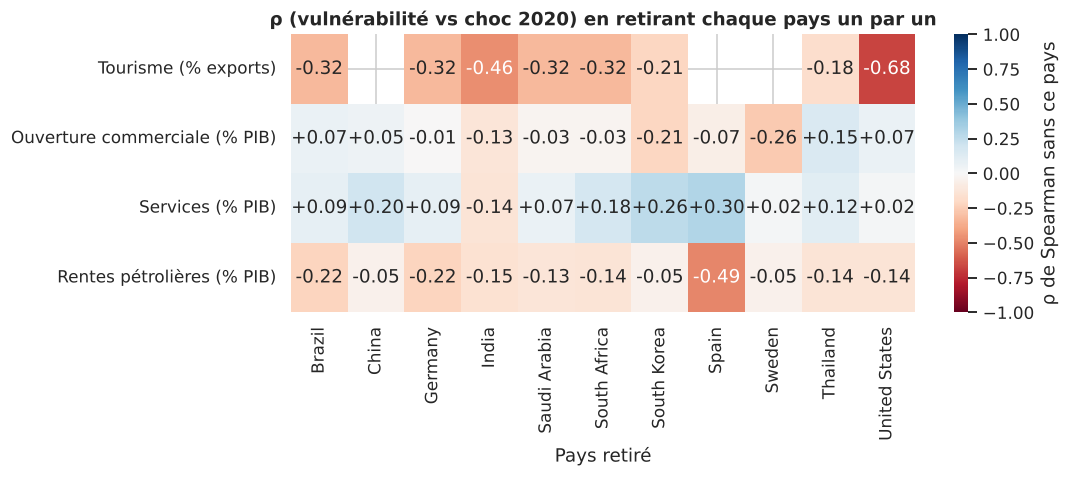

Plage des ρ par variable :
                                min   max
Tourisme (% exports)          -0.68 -0.18
Ouverture commerciale (% PIB) -0.26  0.15
Services (% PIB)              -0.14  0.30
Rentes pétrolières (% PIB)    -0.49 -0.05


In [10]:
def loo(var, target):
    s = d[[var, target]].dropna()
    out = {}
    for c in s.index:
        t = s.drop(c)
        out[c] = stats.spearmanr(t[var], t[target])[0]
    return pd.Series(out)

loo_tab = pd.DataFrame({VARS[v].replace("\n", " "): loo(v, "shortfall_2020") for v in VARS})
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.heatmap(loo_tab.T, annot=True, fmt="+.2f", cmap="RdBu", center=0, vmin=-1, vmax=1, ax=ax,
            cbar_kws={"label": "ρ de Spearman sans ce pays"})
ax.set_title("ρ (vulnérabilité vs choc 2020) en retirant chaque pays un par un")
ax.set_xlabel("Pays retiré"); ax.set_ylabel("")
plt.tight_layout(); plt.show()
print("Plage des ρ par variable :")
print(loo_tab.agg(["min", "max"]).T.round(2))

**Lecture.** Le **tourisme** garde toujours un signe négatif (ρ entre -0,68 et -0,18) : la direction est stable, seule l'intensité varie. Le **commerce** et les **services** changent de signe selon le pays retiré : aucune relation fiable. Le **pétrole** reste négatif en 2020 (choc pétrolier saoudien), mais repose sur un seul pays réellement exposé. À utiliser dans le dashboard comme garde-fou : on montre des *tendances* et des *cas*, pas des lois.

## 5. Comparaisons par groupe

Plutôt que des corrélations, on compare des groupes de pays — c'est souvent plus lisible pour un public non spécialiste.

In [11]:
d["Groupe tourisme"] = np.where(d["tourism_receipts_pct_exports"].isna(), "Donnée manquante",
                        np.where(d["tourism_receipts_pct_exports"] >= d["tourism_receipts_pct_exports"].median(),
                                 "Tourisme élevé", "Tourisme faible"))
d["Groupe commerce"] = np.where(d["trade_pct_gdp"] >= 60, "Très ouvert (≥ 60 % PIB)", "Peu ouvert (< 60 % PIB)")
d["Groupe services"] = np.where(d["services_value_added_pct_gdp"] >= d["services_value_added_pct_gdp"].median(),
                                "Services élevés", "Services faibles")

groupings = ["income_group", "Groupe tourisme", "Groupe commerce", "Groupe services"]
targets = {"shortfall_2020": "Écart 2020 (pts)", "shortfall_2021": "Écart 2021 (pts)",
           "shortfall_2022": "Écart 2022 (pts)", "level_gap_2022": "Écart de niveau fin 2022 (%)"}

summary = pd.concat({g: d.groupby(g)[list(targets)].mean().assign(n=d.groupby(g).size())
                     for g in groupings}).rename(columns=targets)
summary.round(2)

Écart 2020 (pts)  Écart 2021 (pts)  \
income_group    High income                          -5.77              3.53   
                Lower-middle income                 -12.81              2.25   
                Upper-middle income                  -6.29              1.64   
Groupe tourisme Donnée manquante                     -6.55              3.61   
                Tourisme faible                      -6.61              2.24   
                Tourisme élevé                       -6.63              2.55   
Groupe commerce Peu ouvert (< 60 % PIB)              -6.50              3.24   
                Très ouvert (≥ 60 % PIB)             -6.72              2.11   
Groupe services Services faibles                     -6.86              1.83   
                Services élevés                      -6.38              3.47   

                                          Écart 2022 (pts)  \
income_group    High income                           2.48   
                Lower-middle income                   0.17   
                Upper-middle income                  -0.66   
Groupe tourisme Donnée manquante                      0.47   
                Tourisme faible                       0.28   
                Tourisme élevé                        2.46   
Groupe commerce Peu ouvert (< 60 % PIB)               1.52   
                Très ouvert (≥ 60 % PIB)              0.66   
Groupe services Services faibles                      1.21   
                Services élevés                       1.06   

                                          Écart de niveau fin 2022 (%)  n  
income_group    High income                                      -0.09  6  
                Lower-middle income                              -9.98  1  
                Upper-middle income                              -5.20  4  
Groupe tourisme Donnée manquante                                 -2.78  3  
                Tourisme faible                                  -4.04  4  
                Tourisme élevé                                   -1.71  4  
Groupe commerce Peu ouvert (< 60 % PIB)                          -1.84  6  
                Très ouvert (≥ 60 % PIB)                         -4.06  5  
Groupe services Services faibles                                 -3.72  5  
                Services élevés                                  -2.12  6

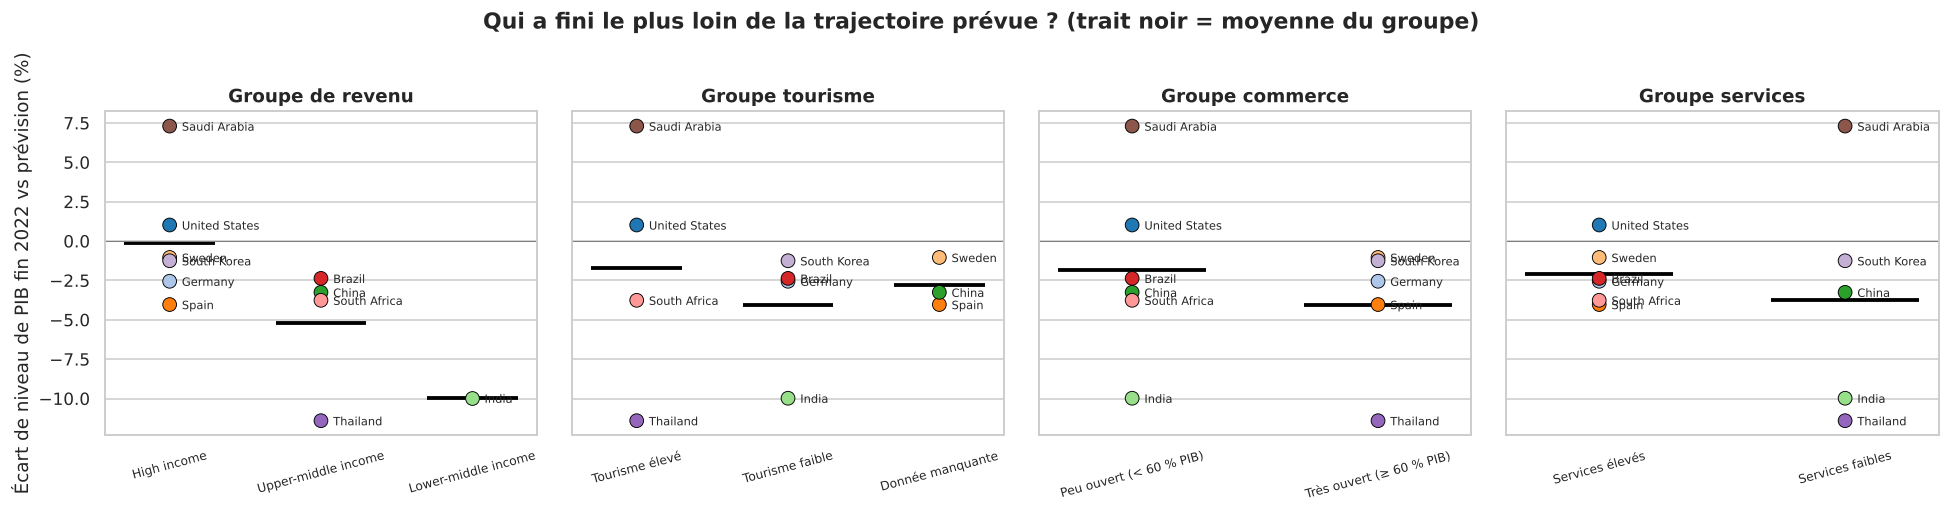

In [12]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5), sharey=True)
for ax, g in zip(axes, groupings):
    sns.stripplot(data=d.reset_index(names="country"), x=g, y="level_gap_2022", hue="country",
                  palette={NAMES[k]: v for k, v in COUNTRY_COLORS.items()}, size=9, jitter=False,
                  edgecolor="black", linewidth=.6, ax=ax, legend=False)
    means = d.groupby(g)["level_gap_2022"].mean()
    for i, lab in enumerate([t.get_text() for t in ax.get_xticklabels()]):
        ax.hlines(means[lab], i - .3, i + .3, color="black", lw=2.5)
    for n, r in d.iterrows():
        xs = [t.get_text() for t in ax.get_xticklabels()].index(r[g])
        ax.annotate(n, (xs, r["level_gap_2022"]), xytext=(8, -3), textcoords="offset points", fontsize=7.5)
    ax.axhline(0, color="grey", lw=.7)
    ax.set_title(g.replace("income_group", "Groupe de revenu"))
    ax.set_xlabel(""); ax.tick_params(axis="x", labelsize=8, rotation=15)
axes[0].set_ylabel("Écart de niveau de PIB fin 2022 vs prévision (%)")
fig.suptitle("Qui a fini le plus loin de la trajectoire prévue ? (trait noir = moyenne du groupe)", fontweight="bold", y=1.03)
plt.tight_layout(); plt.show()

**Lecture.**
- **Groupe de revenu** : c'est la dimension la plus discriminante du panel. Fin 2022, les pays à revenu élevé sont en moyenne pile sur leur trajectoire (≈ 0 %), les pays à revenu intermédiaire supérieur à -5,2 %, et l'Inde (seul pays à revenu intermédiaire inférieur) à -10 %. Même en retirant l'Arabie saoudite, la moyenne des pays riches reste autour de -1,6 % : l'écart avec les pays à revenu intermédiaire tient. C'est le pont naturel vers le chapitre 5 : *la capacité à amortir le choc* (marges budgétaires, soutien aux revenus, accès aux vaccins) compte autant que l'exposition.
- **Tourisme** : en coupant à la médiane, **aucune différence** de choc en 2020 (-6,6 pts dans les deux groupes), et le groupe « tourisme élevé » finit même *mieux* en 2022 — parce qu'il contient l'Arabie saoudite. Le tourisme est donc un récit de **cas** (Thaïlande) plus que de groupe, d'autant que l'Espagne manque.
- **Commerce** : choc 2020 identique, mais les économies très ouvertes finissent plus loin de leur trajectoire en 2022 (-4,1 % contre -1,8 %), un écart porté surtout par la Thaïlande.
- **Services** : différences faibles — l'indicateur est trop agrégé (la « part des services » mélange finance, numérique et hôtellerie).
- ⚠️ L'Arabie saoudite, classée « revenu élevé », tire vers le haut la moyenne de son groupe pour des raisons pétrolières : à mentionner dans une note.

## 6. Vulnérabilité structurelle ou gestion de la crise ? (lien avec les chapitres 2 et 3)

Un pays peut être exposé structurellement mais avoir peu souffert sanitairement, ou avoir imposé des restrictions plus dures. On rapproche donc les vulnérabilités 2019 de trois indicateurs de 2020 :
- **décès COVID cumulés pour 1 million d'habitants** (OWID) — l'intensité du choc sanitaire ;
- **indice de stringence moyen** (OxCGRT) — la dureté des restrictions ;
- **contrôles des voyages internationaux** (OxCGRT, C8, échelle 0–4) — le canal qui frappe directement le tourisme ;
- **indice de soutien économique** (OxCGRT) — la capacité/volonté de compenser.

In [13]:
p20 = policy[policy.Date.dt.year == 2020].groupby("CountryCode").agg(
    stringency_2020=("StringencyIndex_Average", "mean"),
    travel_controls_2020=("C8EV_International travel controls", "mean"),
    econ_support_2020=("EconomicSupportIndex", "mean"))
h20 = health[health.date.dt.year == 2020].groupby("code").agg(
    deaths_per_million_2020=("new_deaths_smoothed_per_million", "sum"))
ctx = p20.join(h20)
ctx.index = ctx.index.map(NAMES)
d = d.join(ctx)

d[["income_group", "tourism_receipts_pct_exports", "trade_pct_gdp", "shortfall_2020",
   "deaths_per_million_2020", "stringency_2020", "travel_controls_2020", "econ_support_2020"]] \
  .sort_values("shortfall_2020").round(1)

,income_group,tourism_receipts_pct_exports,trade_pct_gdp,shortfall_2020,deaths_per_million_2020,stringency_2020,travel_controls_2020,econ_support_2020
ISO3,,,,,,,,
India,Lower-middle income,5.80,39.90,-12.80,103.80,64.80,3.10,48.80
Spain,High income,NaN,66.40,-12.80,"1,121.30",56.30,2.70,68.00
Thailand,Upper-middle income,19.90,109.70,-9.10,1.80,46.10,2.60,69.50
South Africa,Upper-middle income,8.60,53.90,-7.20,431.00,54.50,2.70,47.10
Saudi Arabia,High income,6.90,56.80,-6.00,192.30,57.20,2.90,46.10
Germany,High income,3.50,79.10,-5.40,539.60,51.80,2.60,35.80
Brazil,Upper-middle income,2.40,28.90,-5.30,907.50,57.50,1.90,37.00
United States,High income,9.40,26.30,-4.20,"1,009.30",57.10,2.70,47.80
China,Upper-middle income,NaN,35.50,-3.50,3.40,68.30,2.50,28.70


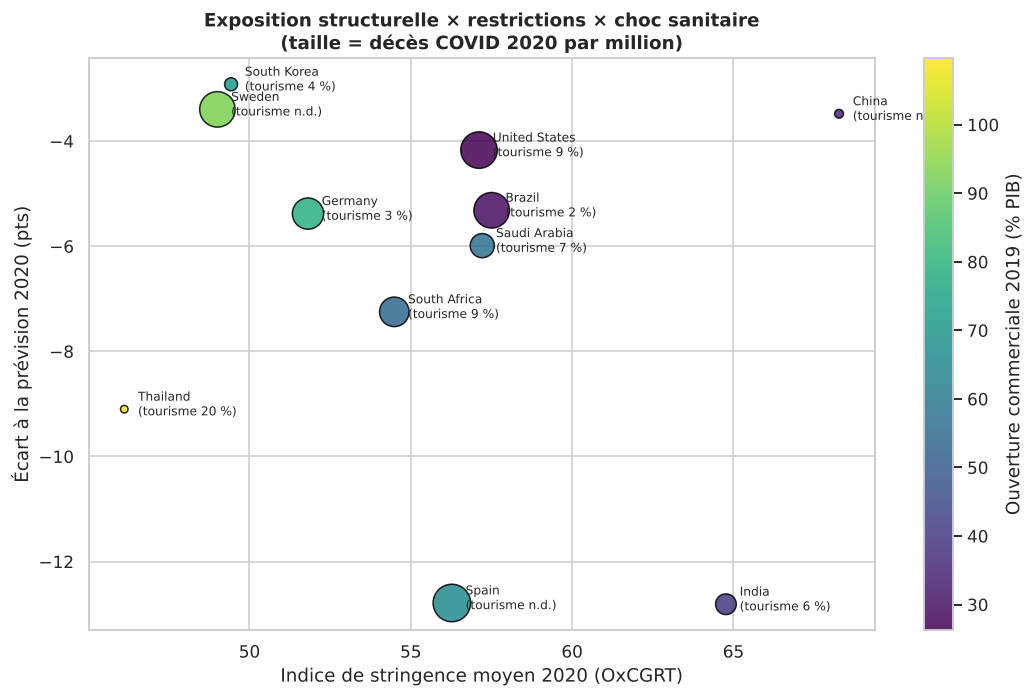

ρ de Spearman avec l'écart 2020 :
 deaths_per_million_2020        -0.02
stringency_2020                -0.15
travel_controls_2020           -0.65
econ_support_2020              -0.69
tourism_receipts_pct_exports   -0.36
trade_pct_gdp                  -0.04
Name: shortfall_2020, dtype: float64


In [14]:
fig, ax = plt.subplots(figsize=(10, 6.5))
sc = ax.scatter(d["stringency_2020"], d["shortfall_2020"],
                s=np.sqrt(d["deaths_per_million_2020"].clip(lower=1)) * 18,
                c=d["trade_pct_gdp"], cmap="viridis", edgecolor="black", alpha=.85)
for n, r in d.iterrows():
    t = r["tourism_receipts_pct_exports"]
    lab = f"{n}\n(tourisme {t:.0f} %)" if pd.notna(t) else f"{n}\n(tourisme n.d.)"
    ax.annotate(lab, (r["stringency_2020"], r["shortfall_2020"]), xytext=(9, -4),
                textcoords="offset points", fontsize=8)
plt.colorbar(sc, label="Ouverture commerciale 2019 (% PIB)")
ax.set_xlabel("Indice de stringence moyen 2020 (OxCGRT)")
ax.set_ylabel("Écart à la prévision 2020 (pts)")
ax.set_title("Exposition structurelle × restrictions × choc sanitaire\n(taille = décès COVID 2020 par million)")
plt.tight_layout(); plt.show()

ctx_corr = d[["shortfall_2020", "deaths_per_million_2020", "stringency_2020",
              "travel_controls_2020", "econ_support_2020", "tourism_receipts_pct_exports", "trade_pct_gdp"]] \
             .corr(method="spearman")["shortfall_2020"].drop("shortfall_2020")
print("ρ de Spearman avec l'écart 2020 :\n", ctx_corr.round(2))

**Lecture.** Ce graphique raconte que *les cartes de départ ne jouent pas seules* :
- La **Thaïlande** a eu très peu de décès en 2020 et des restrictions parmi les plus légères du panel, et pourtant un choc de -9 points : son économie a été frappée **de l'extérieur**, par l'arrêt du tourisme mondial et du commerce. C'est le cas d'école de la vulnérabilité structurelle.
- La **Suède**, très ouverte, a choisi des restrictions légères et a limité le choc économique malgré un bilan sanitaire lourd.
- L'**Inde** combine restrictions dures et choc maximal, avec une exposition extérieure faible : là, c'est la gestion de crise et la fragilité interne qui dominent, pas la structure du commerce.
- Le **Brésil** et les **États-Unis** ont un bilan sanitaire lourd mais un choc économique modéré : ce sont les deux économies les plus fermées du panel.
- La **Chine** a les restrictions les plus dures en moyenne sur 2020, mais un choc limité (épidémie maîtrisée très tôt).

**Ce que disent les corrélations :** le choc 2020 n'est presque pas lié aux décès (ρ ≈ 0) ni à la stringence globale (ρ ≈ -0,15), mais il l'est nettement aux **contrôles des voyages internationaux** (ρ ≈ -0,65) — le canal même par lequel passe la vulnérabilité touristique. Le lien avec le **soutien économique** (ρ ≈ -0,69) est à lire à l'envers : ce sont les pays les plus touchés qui ont le plus soutenu leur économie (causalité inverse), pas le soutien qui aggrave le choc.

### Un test simple : la vulnérabilité ajoute-t-elle quelque chose une fois les restrictions prises en compte ?

Corrélation **partielle** (sur les rangs) entre chaque vulnérabilité et le choc 2020, en neutralisant la stringence. Purement illustratif avec n ≤ 11.

In [15]:
def partial_spearman(x, y, z, data):
    s = data[[x, y, z]].dropna().rank()
    rx = s[x] - np.polyval(np.polyfit(s[z], s[x], 1), s[z])
    ry = s[y] - np.polyval(np.polyfit(s[z], s[y], 1), s[z])
    return stats.pearsonr(rx, ry)[0], len(s)

rows = []
for v, lab in VARS.items():
    raw = stats.spearmanr(*d[[v, "shortfall_2020"]].dropna().T.values)[0]
    part, n = partial_spearman(v, "shortfall_2020", "stringency_2020", d)
    rows.append({"variable": lab.replace("\n", " "), "n": n, "ρ brut": raw, "ρ partiel (contrôle stringence)": part})
pd.DataFrame(rows).set_index("variable").round(2)

,n,ρ brut,ρ partiel (contrôle stringence)
variable,,,
Tourisme (% exports),8,-0.36,-0.45
Ouverture commerciale (% PIB),11,-0.04,-0.29
Services (% PIB),11,0.11,0.07
Rentes pétrolières (% PIB),11,-0.16,-0.13


**Lecture.** La relation tourisme-choc se renforce légèrement une fois la stringence neutralisée (ρ de -0,36 à -0,45), et celle du commerce apparaît (de -0,04 à -0,29). Cela suggère que le tourisme agit **indépendamment** des choix de confinement domestiques : le choc touristique est *importé*. C'est un argument géopolitique fort pour le dashboard : un pays dépendant du reste du monde subit les décisions des autres.

## 7. Le cas pétrolier : une vulnérabilité qui joue dans les deux sens

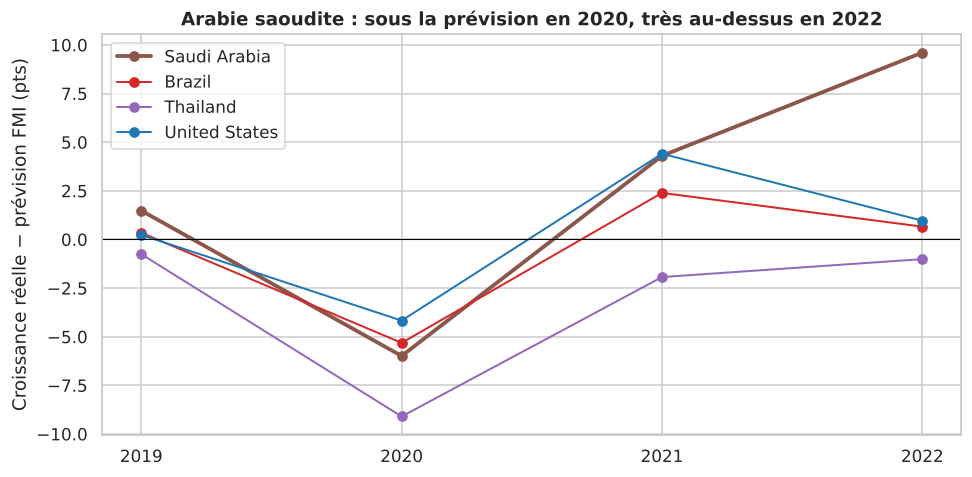

In [16]:
oilc = ["Saudi Arabia", "Brazil", "Thailand", "United States"]
fig, ax = plt.subplots(figsize=(9, 4.5))
for c in oilc:
    s = outcome.loc[c, ["shortfall_2019", "shortfall_2020", "shortfall_2021", "shortfall_2022"]]
    ax.plot([2019, 2020, 2021, 2022], s.values, marker="o", lw=2.5 if c == "Saudi Arabia" else 1.3,
            color=COUNTRY_COLORS[[k for k, v in NAMES.items() if v == c][0]], label=c)
ax.axhline(0, color="black", lw=.7)
ax.set_xticks([2019, 2020, 2021, 2022])
ax.set_ylabel("Croissance réelle − prévision FMI (pts)")
ax.set_title("Arabie saoudite : sous la prévision en 2020, très au-dessus en 2022")
ax.legend(); plt.tight_layout(); plt.show()

**Lecture.** L'Arabie saoudite (rentes pétrolières = 24 % du PIB) chute en 2020 avec l'effondrement de la demande de pétrole, puis dépasse sa prévision de près de 10 points en 2022 grâce à la flambée des prix liée à la reprise mondiale et à la guerre en Ukraine. C'est l'illustration parfaite de la limite du contrefactuel : **l'écart 2022 ne mesure plus le COVID**. Dans le dashboard, on conseille de signaler ce point par une annotation et, pour les comparaisons de « dommage COVID », de privilégier l'écart **2020** ou le cumul **2020-2021**.

## 8. Un biais de départ à garder en tête

Si le FMI se trompait déjà en 2019 (avant le COVID), une partie de l'écart 2020-2022 reflète un optimisme initial, pas la pandémie.

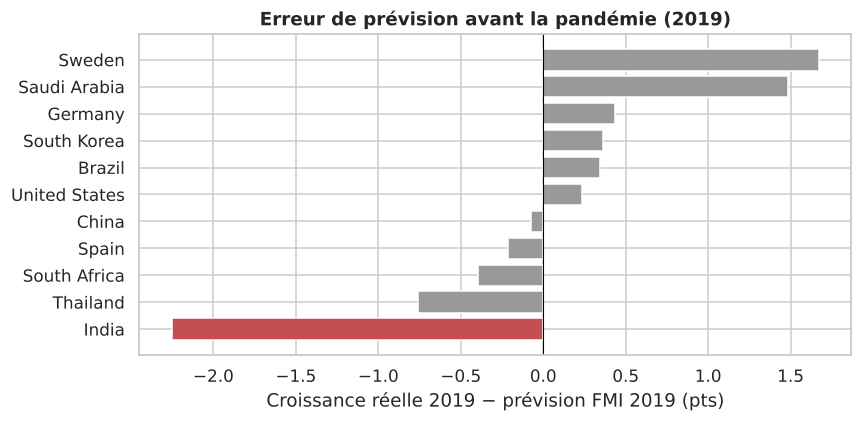

In [17]:
b = outcome["shortfall_2019"].sort_values()
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(b.index, b.values, color=["#c44e52" if x < -1 else "#999999" for x in b.values])
ax.axvline(0, color="black", lw=.7)
ax.set_xlabel("Croissance réelle 2019 − prévision FMI 2019 (pts)")
ax.set_title("Erreur de prévision avant la pandémie (2019)")
plt.tight_layout(); plt.show()

**Lecture.** L'**Inde** était déjà 2,3 points sous la prévision en 2019 : son économie ralentissait avant le COVID, et la prévision pour 2020-2022 (≈ 7 %/an) était probablement trop optimiste. Une partie de son écart cumulé (-10 %) n'est donc pas imputable à la pandémie. À l'inverse, la Suède et l'Arabie saoudite faisaient mieux que prévu en 2019.

## 9. Tableau de synthèse pour le dashboard

On exporte un fichier propre réutilisable dans l'outil de visualisation (Tableau, Power BI, Plotly…), avec les mêmes pays que dans les autres chapitres.

In [18]:
# Indice d'exposition extérieure simple : moyenne des rangs centiles tourisme + commerce
# (si tourisme manquant, on n'utilise que le commerce et on le signale)
pr = d[["tourism_receipts_pct_exports", "trade_pct_gdp"]].rank(pct=True)
d["external_exposure_index"] = pr.mean(axis=1)
d["exposure_index_note"] = np.where(d["tourism_receipts_pct_exports"].isna(), "commerce seul (tourisme n.d.)", "tourisme + commerce")

export = d.reset_index(names="country")[[
    "country", "income_group", "tourism_receipts_pct_exports", "trade_pct_gdp",
    "services_value_added_pct_gdp", "oil_rents_pct_gdp", "external_exposure_index", "exposure_index_note",
    "shortfall_2019", "shortfall_2020", "shortfall_2021", "shortfall_2022", "level_gap_2022",
    "deaths_per_million_2020", "stringency_2020", "travel_controls_2020", "econ_support_2020"]]
export.insert(0, "ISO3", export["country"].map({v: k for k, v in NAMES.items()}))
export.to_csv("chapter4_vulnerability_dataset.csv", index=False)
export.sort_values("level_gap_2022").round(2)

,ISO3,country,income_group,tourism_receipts_pct_exports,trade_pct_gdp,services_value_added_pct_gdp,oil_rents_pct_gdp,external_exposure_index,exposure_index_note,shortfall_2019,shortfall_2020,shortfall_2021,shortfall_2022,level_gap_2022,deaths_per_million_2020,stringency_2020,travel_controls_2020,econ_support_2020
8,THA,Thailand,Upper-middle income,19.88,109.69,58.28,0.46,1.00,tourisme + commerce,-0.76,-9.10,-1.93,-1.01,-11.41,1.80,46.12,2.57,69.47
5,IND,India,Lower-middle income,5.80,39.91,50.08,0.31,0.43,tourisme + commerce,-2.25,-12.81,2.25,0.17,-9.98,103.76,64.77,3.13,48.84
2,ESP,Spain,High income,NaN,66.37,68.27,0.00,0.64,commerce seul (tourisme n.d.),-0.21,-12.79,4.98,4.70,-4.03,"1,121.28",56.27,2.70,68.03
7,ZAF,South Africa,Upper-middle income,8.56,53.90,64.35,0.37,0.60,tourisme + commerce,-0.40,-7.25,3.42,0.30,-3.76,430.98,54.49,2.70,47.06
4,CHN,China,Upper-middle income,NaN,35.45,55.23,0.30,0.27,commerce seul (tourisme n.d.),-0.07,-3.48,2.67,-2.57,-3.26,3.35,68.27,2.47,28.72
1,DEU,Germany,High income,3.47,79.07,63.01,0.01,0.53,tourisme + commerce,0.43,-5.38,2.47,0.47,-2.55,539.57,51.81,2.59,35.76
6,BRA,Brazil,Upper-middle income,2.37,28.89,63.07,1.68,0.15,tourisme + commerce,0.35,-5.32,2.39,0.66,-2.37,907.45,57.51,1.88,37.02
9,KOR,South Korea,High income,3.85,71.45,56.94,0.02,0.55,tourisme + commerce,0.36,-2.92,1.86,-0.17,-1.25,16.09,49.43,2.42,38.73
3,SWE,Sweden,High income,NaN,92.75,65.04,0.03,0.91,commerce seul (tourisme n.d.),1.67,-3.40,3.17,-0.72,-1.04,898.53,49.01,2.50,40.10
0,USA,United States,High income,9.38,26.26,76.61,0.37,0.48,tourisme + commerce,0.23,-4.17,4.41,0.97,1.02,"1,009.30",57.11,2.71,47.81


## 10. Ce qu'il faut retenir pour le chapitre 4

1. **Personne n'est parti avec les mêmes cartes** : la Thaïlande cumule dépendance au tourisme et ouverture commerciale extrême ; l'Arabie saoudite dépend du pétrole ; les États-Unis sont tertiarisés mais fermés.
2. **La vulnérabilité structurelle n'explique qu'une partie de l'histoire.** Aucune variable seule ne classe bien les pays, et avec 11 pays aucune relation n'est statistiquement robuste. Le message honnête pour le public : *l'exposition prédispose, elle ne condamne pas*.
3. **Le tourisme est le canal le plus cohérent** : signe attendu et stable, renforcé par le lien fort entre contrôles des voyages et choc 2020 ; le cas thaïlandais montre un choc « importé » — peu de décès, peu de restrictions, mais une économie qui s'arrête quand le monde cesse de voyager.
4. **L'ouverture au commerce de biens n'a pas été un handicap durable** : les économies industrielles ouvertes (Corée, Allemagne, Suède) ont limité les dégâts.
5. **Le revenu compte** : les pays à revenu intermédiaire finissent plus loin de leur trajectoire que les pays riches — transition naturelle vers le **chapitre 5** sur l'inégalité de la reprise.
6. **Limites à afficher** : tourisme manquant pour l'Espagne, la Suède et la Chine ; écart 2022 saoudien dû au pétrole ; prévision indienne déjà trop optimiste en 2019 ; corrélations descriptives sur un petit panel.

**Visuels recommandés pour le dashboard :** la heatmap des profils (section 3), la bulle tourisme × commerce (section 3), le scatter stringence × choc coloré par exposition (section 6) et le strip plot par groupe de revenu (section 5).